# KMOS — IZ before / after the ZAP fix, grouped by galaxy

Same style and extraction as `kmos_stacked_showcase_group.ipynb`, but every galaxy with
IZ data is shown **twice, side by side**: left with the **old IZ** reduction, right with
the **new IZ** reduction (sky subtraction with the corrected eigenbasis,
`docs/zap-iz-svd-mean-bug.md`).  Other bands of the same galaxy (YJ, H) are identical
on both sides and fill the line panels that IZ does not cover.

* **Fair comparison.**  The old IZ stack is built only from the target lists that are
  also in the new combination, and the aperture sits on the **same sky position** in
  old and new (Hα peak of the reference band, transferred via the WCS).
* **Same scale.**  Old and new IZ spectra are divided by the *same* number (median of
  the new IZ spectrum), and every old/new panel pair shares its y-axis — differences in
  noise are therefore directly visible.
* **Exposure.**  The new combination currently lacks 7 IZ OBs (not yet re-reduced), so
  some galaxies have less on-source time on the right; it is printed on every panel.

**Sections**
1. Settings, helpers
2. Load old + new, match galaxies, common centre
3. Summary — S/N old vs new
4. Line-window gallery — old | new per line
5. Detail view — full spectrum, line zooms and maps, old | new

In [1]:
import os, sys, glob, pathlib, warnings, importlib
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from astropy.io import fits
from astropy.wcs import WCS

# ── data ─────────────────────────────────────────────────────────────────────
OLD_BASE = "kmos_proc_and_comb_server"   # combination before the fix (all bands)
NEW_BASE = "kmos_comb_new_IZ"            # new IZ combination (scripts/edps_pick_jobs.py)
BAND     = "IZ"

# ── extraction (as kmos_stacked_showcase_group) ──────────────────────────────
APERTURE          = 5
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0
HA_REST      = 0.65628
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 2.0

# ── display ──────────────────────────────────────────────────────────────────
TOP_DETAIL   = 20
ZOOM_HALF    = 0.018
HB_ZOOM_HALF = 0.012

PALETTE = ["#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400", "#16a085", "#2c3e50",
           "#e74c3c", "#2980b9", "#1abc9c", "#f39c12", "#7f8c8d", "#6c3483", "#1e8449"]
BAND_COLORS = {'IZ': '#1a6faf', 'YJ': '#27ae60', 'H': '#c03a2b', 'HK': '#8e44ad', 'K': '#d35400'}
OLD_COLOR   = '#8c8c8c'          # old IZ
NEW_COLOR   = BAND_COLORS['IZ']  # new IZ

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})
warnings.filterwarnings("ignore")

In [2]:
# ── helpers (identical extraction / S/N to kmos_stacked_showcase_group) ──────
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr; importlib.reload(_lsnr)
import kmos_sample as ks;  importlib.reload(ks)
from compare_combined import coherent as _coherent

ZCAT = ks.RedshiftCatalog(pathlib.Path("scripts") / "target_redshifts.csv")

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08):
    hp = int(np.argmin(np.abs(wave - HA_REST * (1.0 + z))))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat = ha_im.ravel()
    for idx in np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx] for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px)
    return ifu_center(cube)

def extract_raw(cube, ctr):
    """5×5 box with edge erosion, NOT normalised (normalisation is done per galaxy)."""
    h2 = APERTURE // 2; py, px = ctr
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid = _erode_valid(np.isfinite(patch), EDGE_MARGIN)
    clean = np.where(valid, patch, np.nan)
    spec = np.full(cube.shape[0], np.nan)
    ok = valid.any(axis=1)
    spec[ok] = np.nansum(clean[ok], axis=1)
    return spec

def narrowband_image(cube, wave, z, line_rest, margin=EDGE_MARGIN):
    lam = line_rest * (1.0 + z)
    if not (wave.min() < lam < wave.max()):
        return None
    hp = int(np.argmin(np.abs(wave - lam)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    return np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)

LINE_DEFS = {
    'ha':   (HA_REST,  SNR_WIN_HALF, SNR_CONT_IN, SNR_CONT_OUT),
    'hb':   (0.48627,  0.0020, 0.005, 0.018),
    'oiii': (0.50082,  0.0020, 0.005, 0.018),
    'sii':  (0.67163,  0.0020, 0.005, 0.018),
}
def line_snrs(wave, spec, z):
    return {k: _lsnr.line_snr(wave, spec, z, lr, win_half=wh, cont_in=ci, cont_out=co)
            for k, (lr, wh, ci, co) in LINE_DEFS.items()}

EMISSION_LINES = {
    "[OII]3727": (0.37270, "#e377c2"), "Hβ": (0.48627, "#1f77b4"),
    "[OIII]4959": (0.49594, "#7fdbff"), "[OIII]5007": (0.50082, "#17becf"),
    "Hα": (0.65628, "#d62728"), "[NII]6583": (0.65835, "#ff7f0e"),
    "[SII]6716": (0.67163, "#9467bd"), "[SII]6731": (0.67308, "#c5b0d8"),
}
ZOOM_PANELS = [
    ('ha', HA_REST, r'H$\alpha$', '#d62728', ZOOM_HALF,
     [('[NII]6548', 0.65480, '#ff7f0e', 0.8, ':'), ('[NII]6583', 0.65835, '#ff7f0e', 1.1, '--')]),
    ('hb', 0.48627, r'H$\beta$', '#1f77b4', HB_ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':')]),
    ('oiii', 0.50082, r'[OIII]$\lambda$5007', '#17becf', ZOOM_HALF,
     [('[OIII]4959', 0.49594, '#7fdbff', 0.8, ':'), (r'H$\beta$', 0.48627, '#1f77b4', 0.8, '--')]),
    ('sii', 0.67163, r'[SII]$\lambda$6716', '#9467bd', ZOOM_HALF,
     [(r'H$\alpha$', HA_REST, '#d62728', 1.2, '--'), ('[NII]6583', 0.65835, '#ff7f0e', 0.9, ':'),
      ('[SII]6731', 0.67308, '#c5b0d8', 0.9, ':')]),
]
PLAIN = {'ha': 'Hα', 'hb': 'Hβ', 'oiii': '[OIII]5007', 'sii': '[SII]6716'}

def covers(m, lrest, z):
    return m['wave'].min() < lrest * (1.0 + z) < m['wave'].max()

def has_data(m, lrest, z, half=0.0015):
    """Line inside the band AND finite data at its position (IZ starts ~7800 Å with NaNs)."""
    if not covers(m, lrest, z):
        return False
    lam = lrest * (1.0 + z)
    win = np.abs(m['wave'] - lam) < half
    return bool(np.isfinite(m['med'][win]).sum() >= 0.5 * win.sum()) if win.any() else False

def fin(v, default=-np.inf):
    return v if (v is not None and np.isfinite(v)) else default

def restack(paths):
    """Exposure-weighted, sky-aligned stack of a subset of combined cubes."""
    cubes, wcss, w = [], [], []
    for p in paths:
        with fits.open(p) as hf:
            cubes.append(np.array(hf["DATA"].data, dtype=np.float32))
            wcss.append(WCS(hf["DATA"].header).celestial)
            t = ks.onsource_seconds(hf[0].header)
            w.append(t if np.isfinite(t) and t > 0 else 1.0)
    cube, (sy0, sx0) = ks._stack(cubes, w, wcss)
    wcs = wcss[0].deepcopy(); wcs.wcs.crpix = wcs.wcs.crpix + np.array([sx0, sy0])
    return cube, wcs, float(np.nansum(w))

def to_pix(wcs_from, ctr, wcs_to, shape):
    cy, cx = ctr
    ra, dec = wcs_from.pixel_to_world_values(cx, cy)
    px, py = wcs_to.world_to_pixel_values(ra, dec)
    iy, ix = int(round(float(py))), int(round(float(px)))
    return (iy, ix) if (0 <= iy < shape[0] and 0 <= ix < shape[1]) else None

## Load old + new, match galaxies, common centre

In [3]:
old_stacks = ks.load_galaxy_band_stacks(OLD_BASE, ZCAT, normalise=False)
new_stacks = ks.load_galaxy_band_stacks(NEW_BASE, ZCAT, normalise=False)
old_by = {(s['field'], s['tid'], s['band']): s for s in old_stacks}
new_iz = {(s['field'], s['tid']): s for s in new_stacks if s['band'] == BAND}

def member(kind, band, wave, cube, wcs, exptime_s):
    return dict(kind=kind, band=band, wave=wave, cube=np.asarray(cube, float), wcs=wcs,
                exptime_s=exptime_s)

galaxies = []
for (field, tid), n in sorted(new_iz.items()):
    o = old_by.get((field, tid, BAND))
    if o is None:
        continue
    # old IZ only from the target lists that are also in the new combination
    paths = [p for p in o['paths'] if ks.cube_info(p, ZCAT)['target_list'] in n['target_lists']]
    if not paths:
        continue
    if len(paths) == len(o['paths']):
        o_cube, o_wcs, o_t = o['cube'], o['wcs'], o['exptime_s']
    else:
        o_cube, o_wcs, o_t = restack(paths)
    z = n['z']
    iz_old = member('old', BAND, o['wave'], o_cube, o_wcs, o_t)
    iz_new = member('new', BAND, n['wave'], n['cube'], n['wcs'], n['exptime_s'])
    others = [member('both', b, s['wave'], s['cube'], s['wcs'], s['exptime_s'])
              for (f, t, b), s in old_by.items() if f == field and t == tid and b != BAND]
    others.sort(key=lambda m: ks.band_rank(m['band']))

    # reference for the centre: new IZ if it covers Hα, else the deepest other band with Hα
    ha_cands = [m for m in [iz_new] + others if covers(m, HA_REST, z)]
    ref = iz_new if iz_new in ha_cands else (max(ha_cands, key=lambda m: m['exptime_s']) if ha_cands else iz_new)
    if covers(ref, HA_REST, z):
        c = ha_peak_center(ref['cube'], ref['wave'], z)
        g0 = ifu_center(ref['cube'])
        fb = np.hypot(c[0] - g0[0], c[1] - g0[1]) > MAX_CENTER_OFFSET
        ref['ctr'] = g0 if fb else c
        ref['ctr_src'] = f"Hα peak ({ref['band']}{' new' if ref is iz_new else ''})" + (" [fb → centre]" if fb else "")
    else:
        ref['ctr'] = ifu_center(ref['cube'])
        ref['ctr_src'] = "IFU centre (no Hα in any band)"
    for m in [iz_old, iz_new] + others:
        if m is ref:
            continue
        c = to_pix(ref['wcs'], ref['ctr'], m['wcs'], m['cube'].shape[1:])
        m['ctr'] = c if c is not None else ifu_center(m['cube'])
        m['ctr_src'] = f"from {ref['band']}{' new' if ref is iz_new else ''} (WCS)" if c is not None else "IFU centre"

    # spectra: old and new IZ divided by the SAME number (median of the new IZ spectrum)
    for m in [iz_old, iz_new] + others:
        m['raw'] = extract_raw(m['cube'], m['ctr'])
    def _norm(s):
        r = np.nanmedian(s)
        return r if (np.isfinite(r) and r > 0) else (np.nanmedian(np.abs(s)) or 1.0)
    iz_norm = _norm(iz_new['raw'])
    for m in [iz_old, iz_new]:
        m['med'] = m['raw'] / iz_norm
    for m in others:
        m['med'] = m['raw'] / _norm(m['raw'])
    for m in [iz_old, iz_new] + others:
        m['snr'] = line_snrs(m['wave'], m['med'], z)
        yy, xx = np.mgrid[:m['cube'].shape[1], :m['cube'].shape[2]]
        m['coh'] = _coherent(m['cube'], np.hypot(yy - m['ctr'][0], xx - m['ctr'][1]) <= 2)

    sides = {'old': [iz_old] + others, 'new': [iz_new] + others}
    use, snr = {}, {}
    for side, mem in sides.items():
        use[side], snr[side] = {}, {}
        for k, lrest, *_ in ZOOM_PANELS:
            iz = mem[0]
            if has_data(iz, lrest, z):                    # IZ first — that is what we compare
                u = iz
            else:
                c = [m for m in mem[1:] if has_data(m, lrest, z)]
                u = max(c, key=lambda m: m['exptime_s']) if c else None
            use[side][k] = u
            snr[side][k] = u['snr'][k] if u is not None else np.nan
    galaxies.append(dict(
        field=field, tid=tid, z=z, z_type=n['z_type'], iz_old=iz_old, iz_new=iz_new, others=others,
        sides=sides, use=use, snr=snr,
        # ranking / selection only by lines measured in IZ (other bands are identical old/new)
        best_old=max([fin(snr['old'][k]) for k in snr['old'] if use['old'][k] is iz_old] or [-np.inf]),
        best_new=max([fin(snr['new'][k]) for k in snr['new'] if use['new'][k] is iz_new] or [-np.inf]),
    ))

galaxies.sort(key=lambda g: max(g['best_new'], g['best_old']), reverse=True)
print(f"{len(galaxies)} galaxies with {BAND} in old and new "
      f"({sum(len(g['others']) > 0 for g in galaxies)} with other bands)")
print(f"\n{'#':>3}  {'galaxy':16} {'z':>6}  {'t old/new [h]':>13}  {'coh old/new':>11}   "
      + "  ".join(f"{PLAIN[k]:>15}" for k, *_ in ZOOM_PANELS))
print("-" * 120)
def _c(g, k):
    o, n, u = g['snr']['old'][k], g['snr']['new'][k], g['use']['new'][k]
    if u is None:
        return f"{'—':>15}"
    tag = '' if u['band'] == BAND else f" {u['band']}"
    return f"{o:5.1f} → {n:5.1f}{tag}".rjust(15)
for i, g in enumerate(galaxies):
    print(f"{i+1:>3}  {g['field'] + ' ' + g['tid']:16} {g['z']:6.3f}  "
          f"{g['iz_old']['exptime_s']/3600:5.1f} / {g['iz_new']['exptime_s']/3600:4.1f}  "
          f"{g['iz_old']['coh']:5.1f} / {g['iz_new']['coh']:4.1f}   "
          + "  ".join(_c(g, k) for k, *_ in ZOOM_PANELS))

kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


kmos_comb_new_IZ: 44 combined cubes, 0 without redshift
  → 44 galaxies, 44 (galaxy, band) stacks, 0 stacked from >1 cube   CDFS: 22  COSMOS: 22


44 galaxies with IZ in old and new (22 with other bands)

  #  galaxy                z  t old/new [h]  coh old/new                Hα               Hβ       [OIII]5007        [SII]6716
------------------------------------------------------------------------------------------------------------------------
  1  CDFS 23420        0.605   10.7 /  8.7    5.2 /  1.2      39.2 → 190.4                —     13.8 →  35.8     10.3 →  24.1
  2  COSMOS 92754      0.626    8.0 /  8.0    3.7 /  1.2      25.1 →  74.9      1.4 →   2.0      2.0 →   7.2   13.5 →  13.5 YJ
  3  COSMOS 85939      0.636    9.5 /  8.0    9.8 /  1.2       5.7 →  12.6     -5.5 →   4.0      2.1 →  -2.1    3.7 →   3.7 YJ
  4  CDFS 22737        0.648   10.7 /  8.7    6.2 /  1.2       0.7 →  12.5      6.5 →   3.0      0.0 →   3.0                —
  5  CDFS 23840        0.648   10.7 /  8.7    5.7 /  1.3       2.2 →  12.2      3.7 →   2.3      0.7 →   2.8                —
  6  CDFS 22992        0.607   10.7 /  8.7    6.8 /  1.2       

## Summary — S/N old vs new

Only lines measured **in IZ** (lines from other bands are identical on both sides).
Left: line S/N old vs new (dashed: 1 : 1).  Right: coherent background residual of the
IZ cube (robust rms of the median background spectrum / expected noise; ≈ 1 for pure
noise).  Very large jumps of faint lines at the band edge (e.g. Hβ right at the blue end
of IZ) can be fit artefacts — check them in the gallery below.

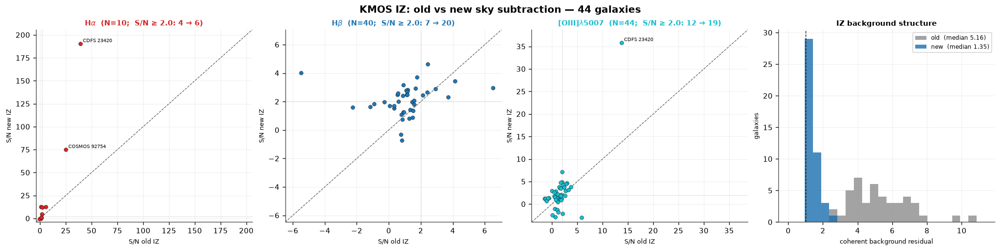

Saved → kmos_iz_compare_summary.pdf


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), constrained_layout=True)
for ax, (k, lrest, label, lc, *_) in zip(axes[:3], ZOOM_PANELS[:3]):
    pts = [(g['snr']['old'][k], g['snr']['new'][k], g) for g in galaxies
           if g['use']['new'][k] is not None and g['use']['new'][k]['band'] == BAND
           and np.isfinite(g['snr']['old'][k]) and np.isfinite(g['snr']['new'][k])]
    if not pts:
        ax.set_visible(False); continue
    o = np.array([p[0] for p in pts]); n = np.array([p[1] for p in pts])
    ax.scatter(o, n, s=22, color=lc, edgecolor='k', lw=0.3, zorder=3)
    lim = (min(o.min(), n.min(), -3) - 1, max(o.max(), n.max(), SNR_MIN * 3) * 1.08)
    ax.plot(lim, lim, '--', color='#666', lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    for v in (SNR_MIN,):
        ax.axhline(v, color='#aaa', lw=0.6, ls=':'); ax.axvline(v, color='#aaa', lw=0.6, ls=':')
    for oo, nn, g in pts:
        if max(oo, nn) >= (20 if k == 'ha' else 8):
            ax.annotate(f"{g['field']} {g['tid']}", (oo, nn), fontsize=6, xytext=(3, 2),
                        textcoords='offset points')
    det_o, det_n = (o >= SNR_MIN).sum(), (n >= SNR_MIN).sum()
    ax.set_title(f"{label}  (N={len(o)};  S/N ≥ {SNR_MIN}: {det_o} → {det_n})", color=lc)
    ax.set_xlabel("S/N old IZ"); ax.set_ylabel("S/N new IZ")
ax = axes[3]
co = np.array([g['iz_old']['coh'] for g in galaxies]); cn = np.array([g['iz_new']['coh'] for g in galaxies])
bins = np.linspace(0, max(np.nanmax(co), np.nanmax(cn)) * 1.05, 25)
ax.hist(co, bins, color=OLD_COLOR, alpha=0.8, label=f"old  (median {np.nanmedian(co):.2f})")
ax.hist(cn, bins, color=NEW_COLOR, alpha=0.8, label=f"new  (median {np.nanmedian(cn):.2f})")
ax.axvline(1, color='k', lw=0.8, ls='--')
ax.set_xlabel("coherent background residual"); ax.set_ylabel("galaxies")
ax.set_title("IZ background structure"); ax.legend(fontsize=7)
fig.suptitle(f"KMOS {BAND}: old vs new sky subtraction — {len(galaxies)} galaxies",
             fontsize=12, fontweight='bold')
plt.savefig('kmos_iz_compare_summary.pdf', bbox_inches='tight')
plt.show()
print('Saved → kmos_iz_compare_summary.pdf')

## Line-window gallery — old | new per line

One row per galaxy (an **IZ** line at S/N ≥ `SNR_MIN` in old **or** new), sorted by the best IZ line.  For every line two
panels: old (grey) and new (blue), sharing the y-axis.  Band tag top-left; lines from
YJ/H are the same on both sides.

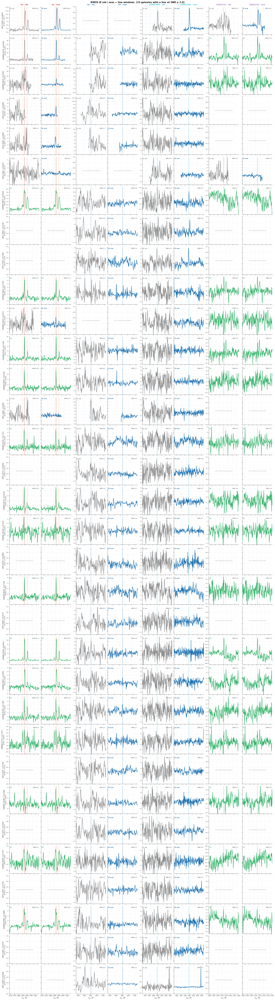

Saved → kmos_iz_compare_gallery.pdf


In [5]:
show = [g for g in galaxies if g['z_type'] in ('spec', 'cluster')
        and max(g['best_old'], g['best_new']) >= SNR_MIN]

def _panel(ax, m, lkey, lrest, label, lc, zhalf, companions, z, color, ylim=None):
    lam = lrest * (1.0 + z); wlo, whi = lam - zhalf, lam + zhalf
    ax.set_xlim(wlo * 1e4, whi * 1e4)
    if m is None:
        ax.text(0.5, 0.5, 'not covered by any band', ha='center', va='center',
                transform=ax.transAxes, fontsize=7, color='#aaa', style='italic')
        return
    w = m['wave']; mask = (w >= wlo) & (w <= whi)
    ax.plot(w[mask] * 1e4, m['med'][mask], color=color, lw=1.6, zorder=3)
    ax.axvline(lam * 1e4, color=lc, lw=1.3, ls='--', alpha=0.85, zorder=2)
    for cname, crest, clc, clw, cls in companions:
        co = crest * (1.0 + z)
        if wlo <= co <= whi:
            ax.axvline(co * 1e4, color=clc, lw=clw, ls=cls, alpha=0.75, zorder=2)
    if ylim is not None:
        ax.set_ylim(*ylim)
    v = m['snr'][lkey]
    ax.text(0.98, 0.96, f"SNR={v:.1f}" if np.isfinite(v) else "SNR=—", transform=ax.transAxes,
            ha='right', va='top', fontsize=6.5, color='#333', bbox=dict(fc='white', ec='none', alpha=0.7, pad=1))
    tag = (f"{m['band']} {'old' if m['kind']=='old' else 'new'}" if m['band'] == BAND else m['band'])
    ax.text(0.02, 0.96, tag, transform=ax.transAxes, ha='left', va='top', fontsize=7,
            fontweight='bold', color=color, bbox=dict(fc='white', ec='none', alpha=0.7, pad=1))

def _pair_ylim(ms, lrest, zhalf, z, lo=2, hi=99.5, padf=0.18):
    vals = []
    for m in ms:
        if m is None:
            continue
        lam = lrest * (1 + z); w = m['wave']
        f = m['med'][(w >= lam - zhalf) & (w <= lam + zhalf)]
        vals.append(f[np.isfinite(f)])
    vals = np.concatenate(vals) if vals else np.array([])
    if not vals.size:
        return None
    a, b = np.percentile(vals, [lo, hi]); p = padf * max(b - a, 1e-6)
    return a - p, b + p

def _col(m):
    return OLD_COLOR if m is not None and m['kind'] == 'old' else (
        NEW_COLOR if m is not None and m['kind'] == 'new' else BAND_COLORS.get(m['band'], '#333') if m else '#333')

if not show:
    print("nothing to show")
else:
    nrows, ncols = len(show), 2 * len(ZOOM_PANELS)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.5, nrows * 2.2), constrained_layout=True)
    axes = np.atleast_2d(axes)
    fig.suptitle(f"KMOS {BAND} old | new — line windows  ({nrows} galaxies with a line at SNR ≥ {SNR_MIN})",
                 fontsize=12, fontweight='bold', y=1.002)
    for ci, (_, _, label, lc, _, _) in enumerate(ZOOM_PANELS):
        axes[0, 2*ci].set_title(f"{label} · old", fontsize=9, color=lc, pad=8)
        axes[0, 2*ci+1].set_title(f"{label} · new", fontsize=9, color=lc, pad=8)
    for ri, g in enumerate(show):
        z = g['z']
        for ci, (lkey, lrest, label, lc, zhalf, comp) in enumerate(ZOOM_PANELS):
            mo, mn = g['use']['old'][lkey], g['use']['new'][lkey]
            yl = _pair_ylim([mo, mn], lrest, zhalf, z)
            for j, m in enumerate((mo, mn)):
                ax = axes[ri, 2*ci + j]
                _panel(ax, m, lkey, lrest, label, lc, zhalf, comp, z, _col(m), yl)
                ax.tick_params(labelsize=5.5)
                if ri < nrows - 1:
                    ax.set_xticklabels([])
                if j == 1:
                    ax.set_yticklabels([])
        axes[ri, 0].set_ylabel(f"{g['field']} {g['tid']}  z={z:.4f}\n"
                               f"IZ {g['iz_old']['exptime_s']/3600:.1f} → {g['iz_new']['exptime_s']/3600:.1f} h",
                               fontsize=7, labelpad=4)
    for ci in range(ncols):
        axes[-1, ci].set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=7)
    plt.savefig('kmos_iz_compare_gallery.pdf', bbox_inches='tight')
    plt.show()
    print('Saved → kmos_iz_compare_gallery.pdf')

## Detail view — old | new

Left half old IZ, right half new IZ (other bands identical).  Top: full spectrum of all
bands; middle: line zooms (IZ first, else the deepest band covering the line); bottom:
IZ white-light and line maps, the box is the 5×5 extraction aperture.  Old and new
share every y-axis.

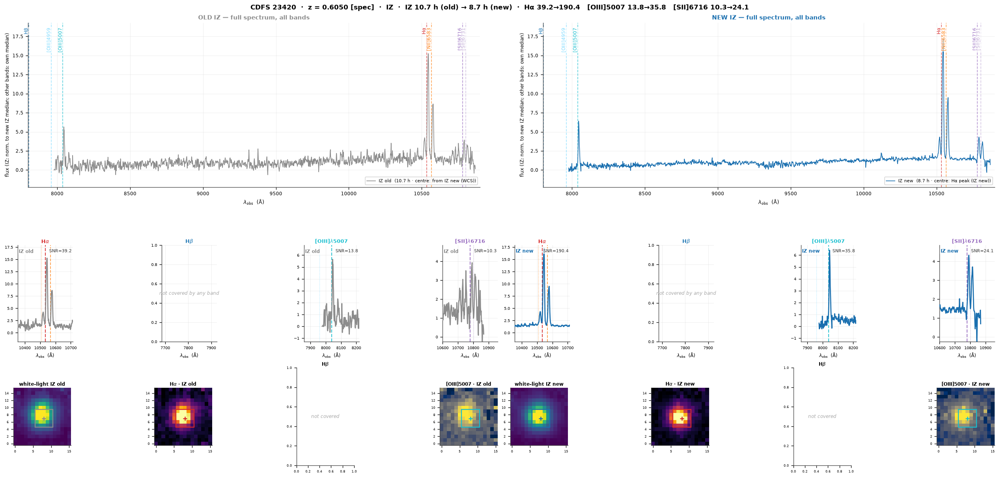

Saved → kmos_iz_compare_detail_CDFS_23420.pdf


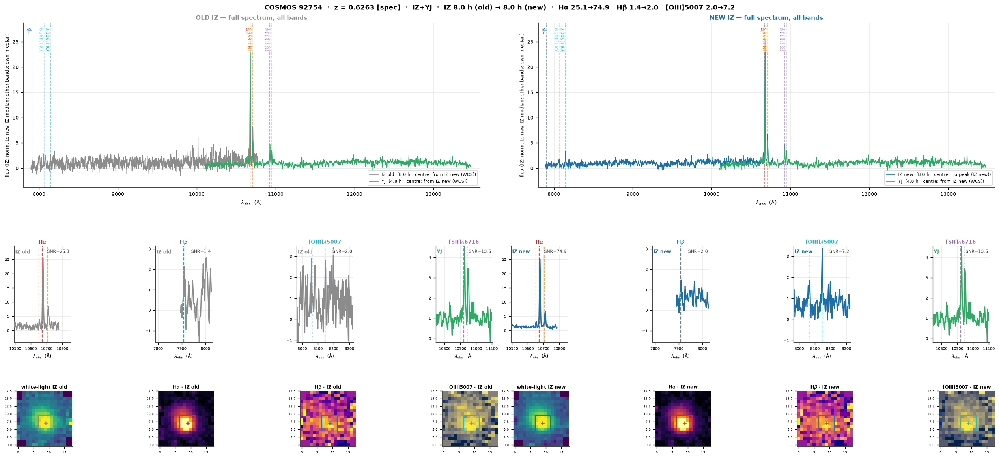

Saved → kmos_iz_compare_detail_COSMOS_92754.pdf


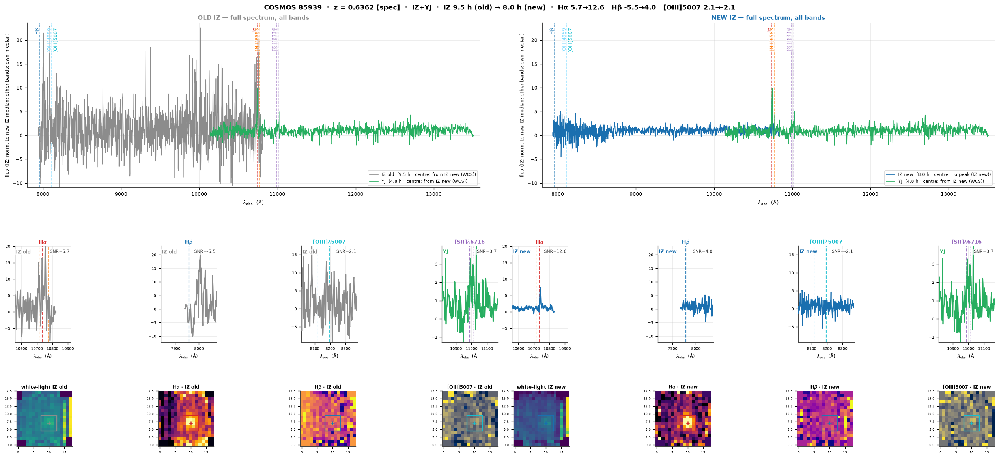

Saved → kmos_iz_compare_detail_COSMOS_85939.pdf


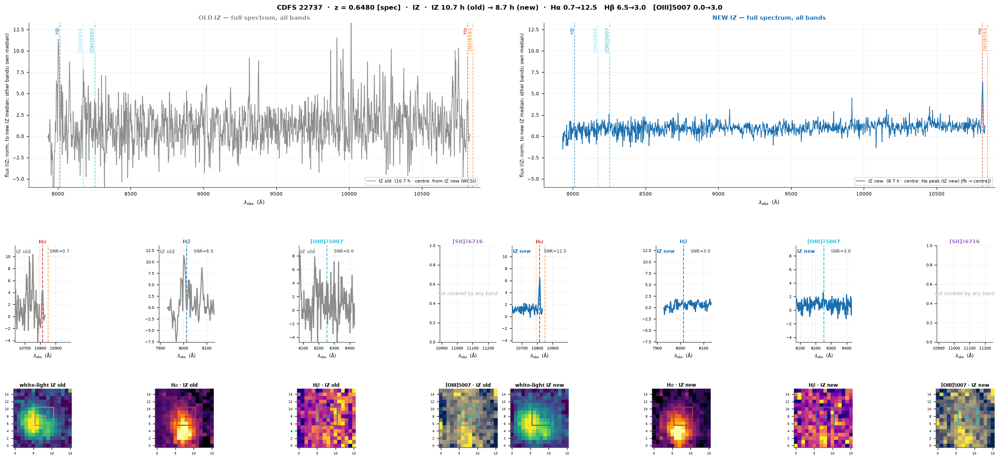

Saved → kmos_iz_compare_detail_CDFS_22737.pdf


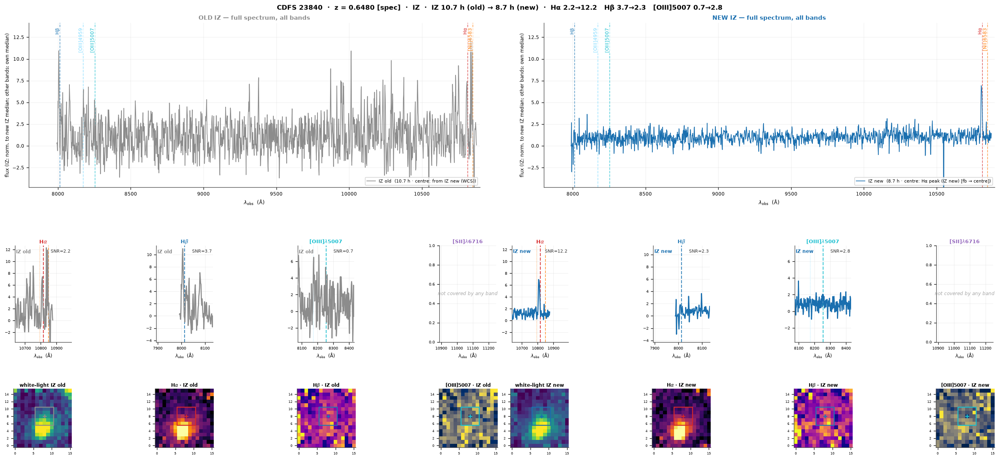

Saved → kmos_iz_compare_detail_CDFS_23840.pdf


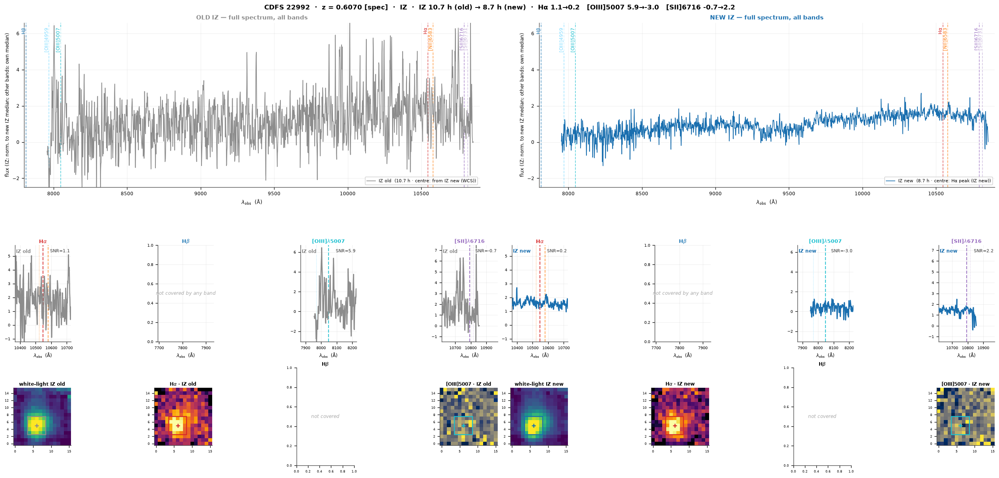

Saved → kmos_iz_compare_detail_CDFS_22992.pdf


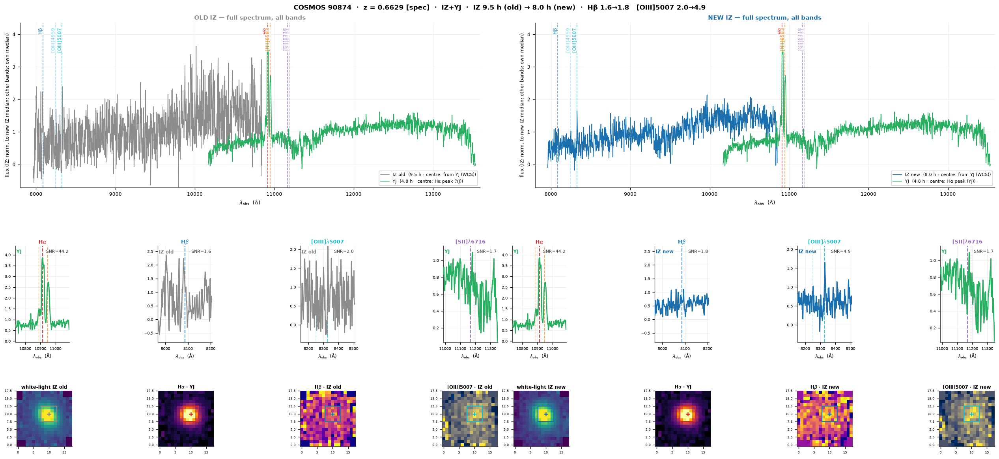

Saved → kmos_iz_compare_detail_COSMOS_90874.pdf


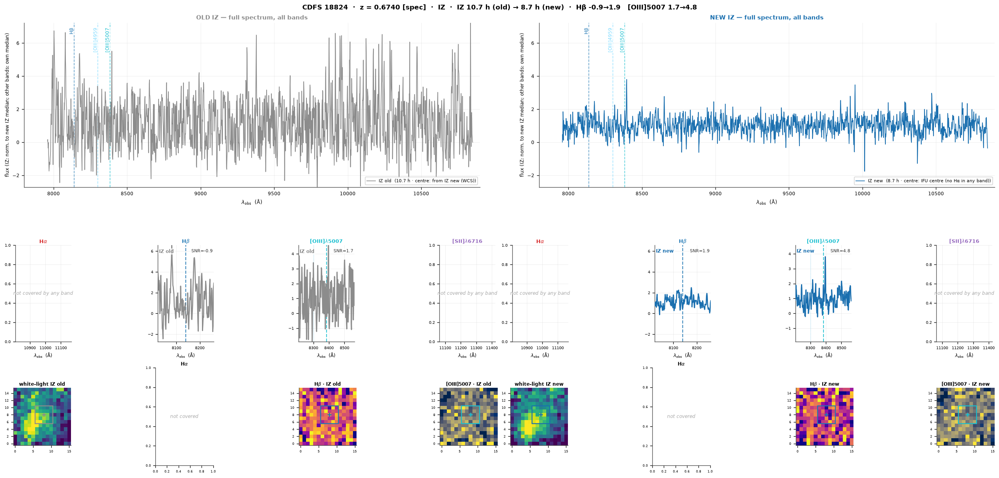

Saved → kmos_iz_compare_detail_CDFS_18824.pdf


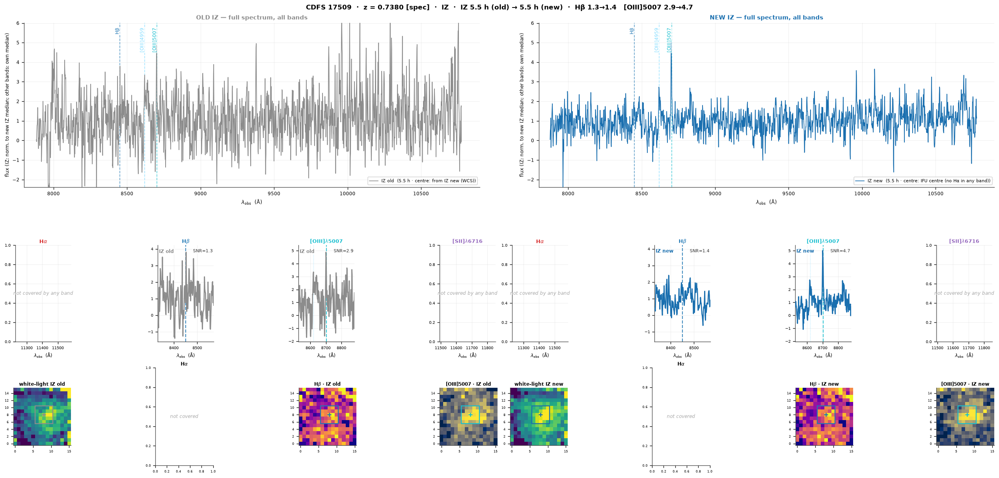

Saved → kmos_iz_compare_detail_CDFS_17509.pdf


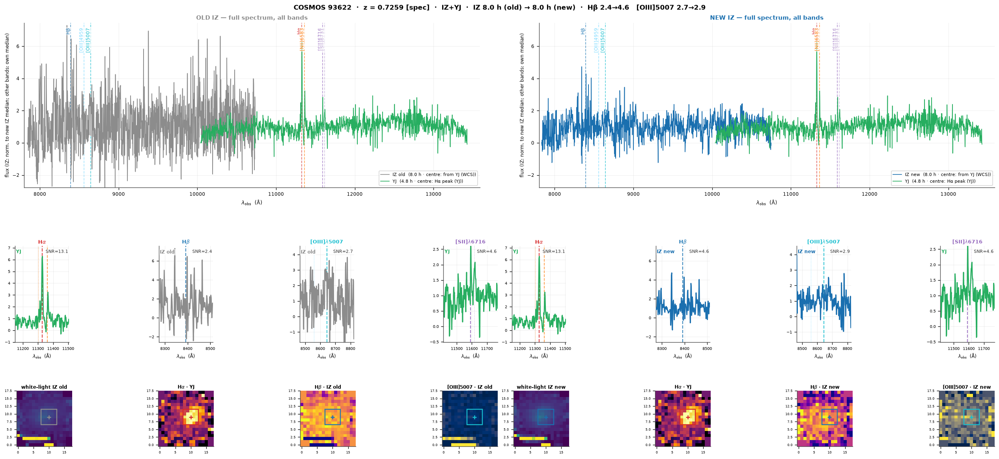

Saved → kmos_iz_compare_detail_COSMOS_93622.pdf


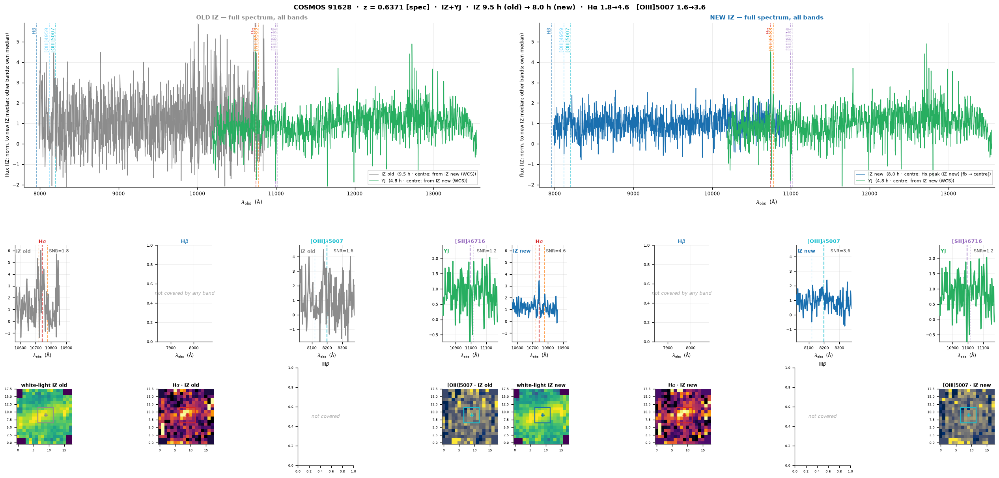

Saved → kmos_iz_compare_detail_COSMOS_91628.pdf


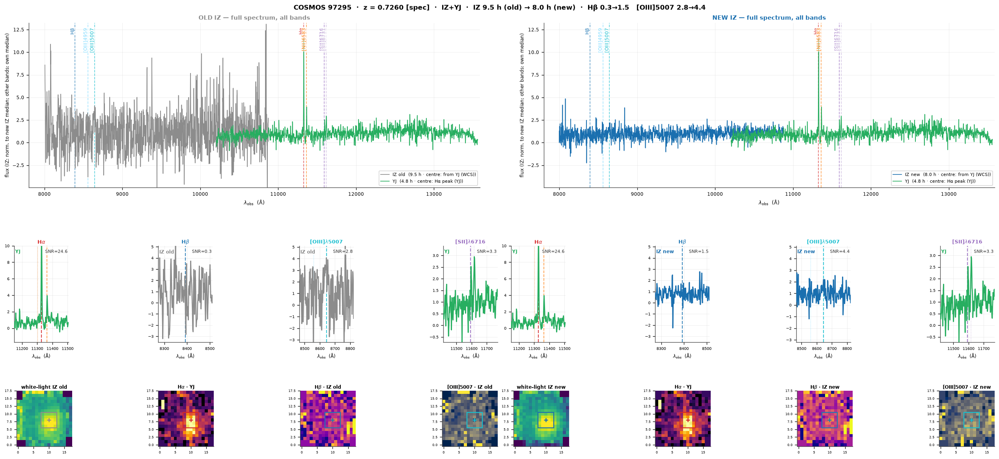

Saved → kmos_iz_compare_detail_COSMOS_97295.pdf


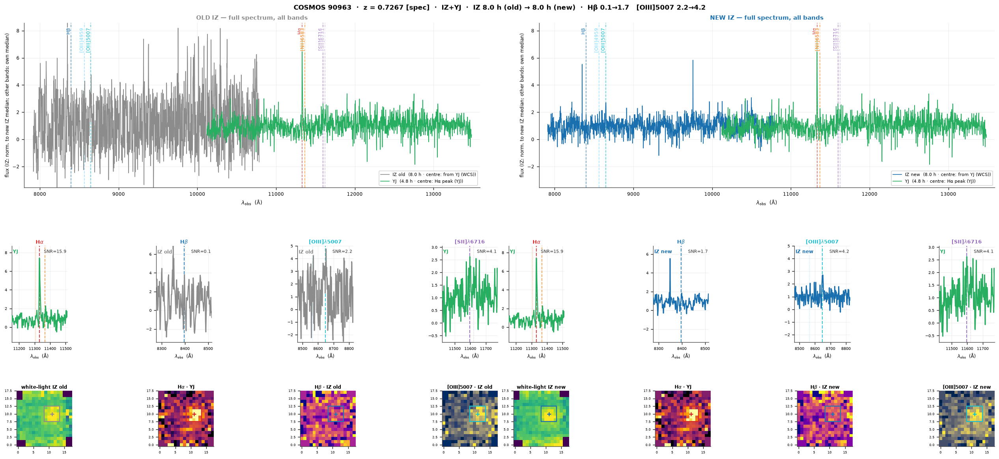

Saved → kmos_iz_compare_detail_COSMOS_90963.pdf


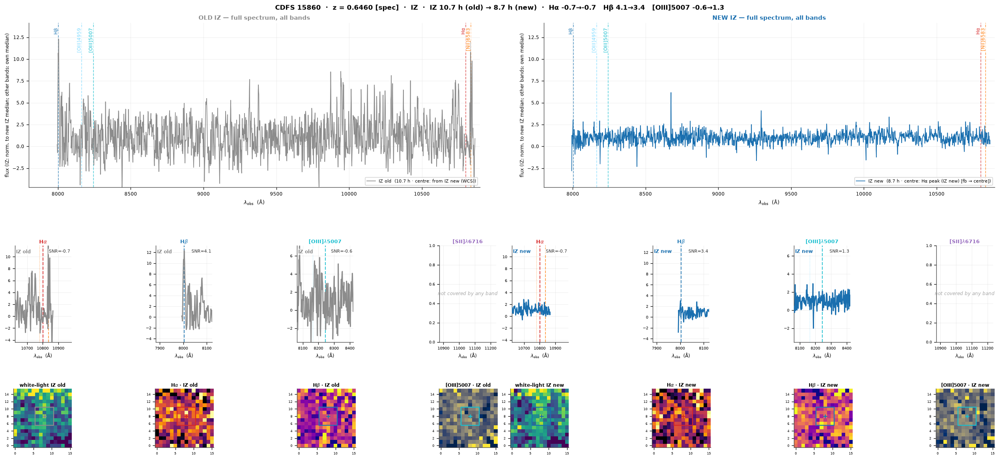

Saved → kmos_iz_compare_detail_CDFS_15860.pdf


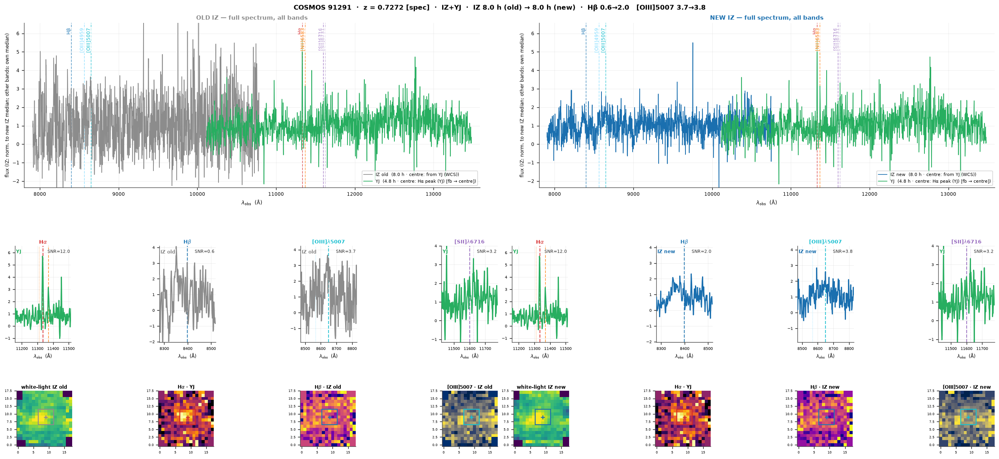

Saved → kmos_iz_compare_detail_COSMOS_91291.pdf


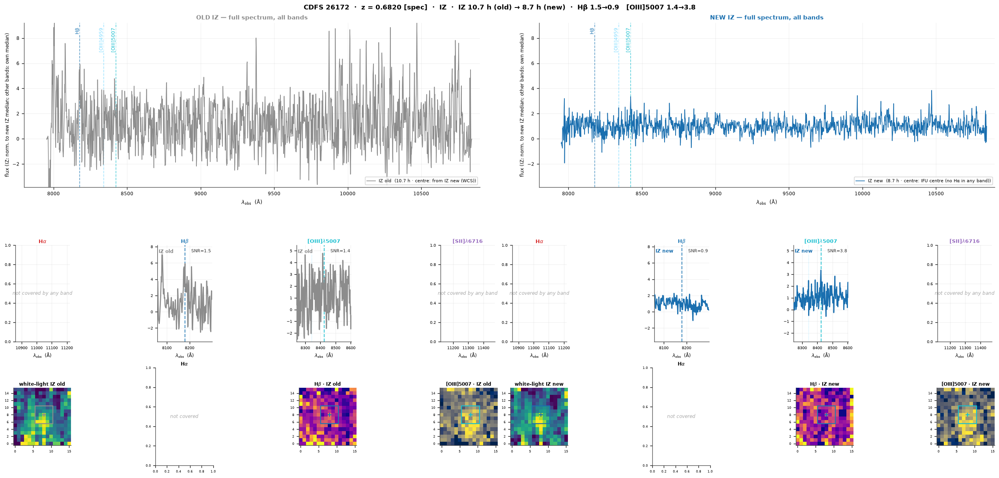

Saved → kmos_iz_compare_detail_CDFS_26172.pdf


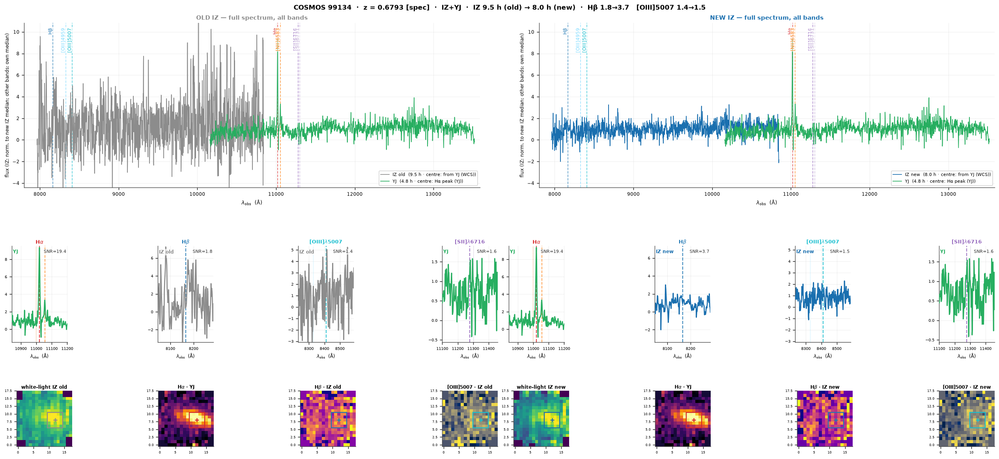

Saved → kmos_iz_compare_detail_COSMOS_99134.pdf


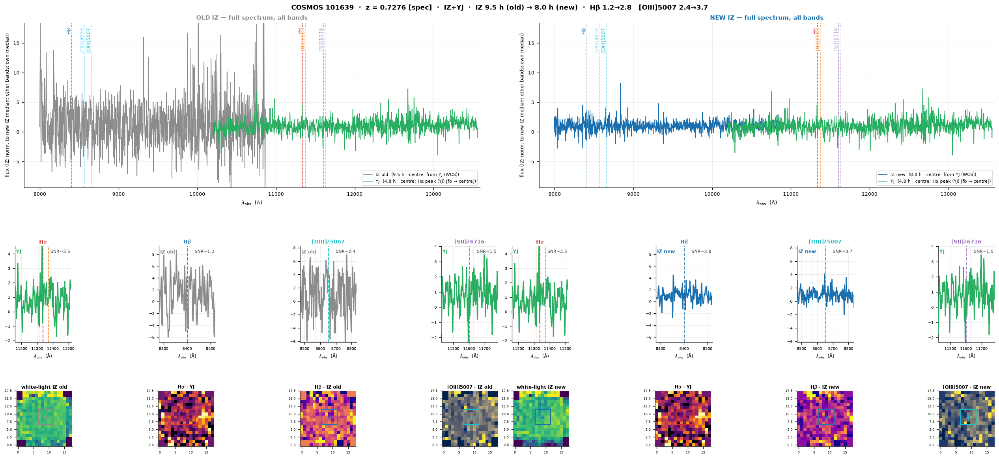

Saved → kmos_iz_compare_detail_COSMOS_101639.pdf


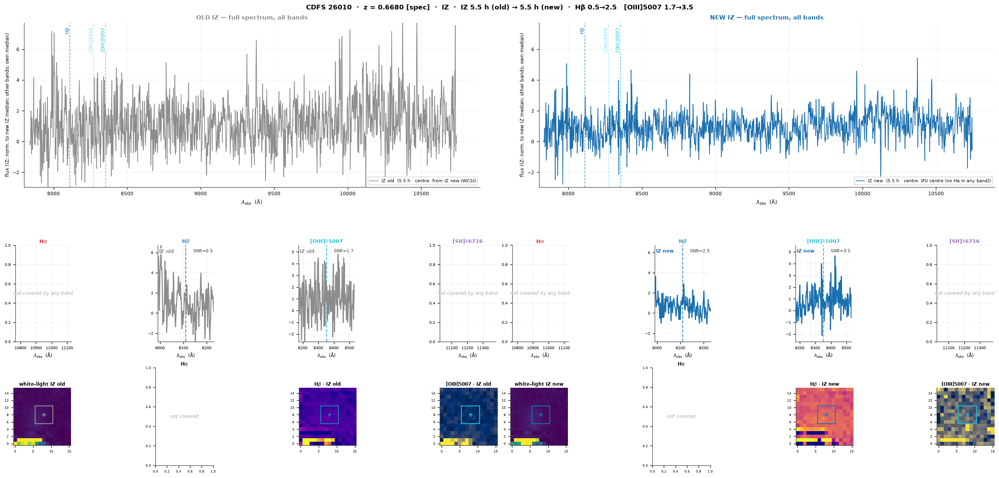

Saved → kmos_iz_compare_detail_CDFS_26010.pdf


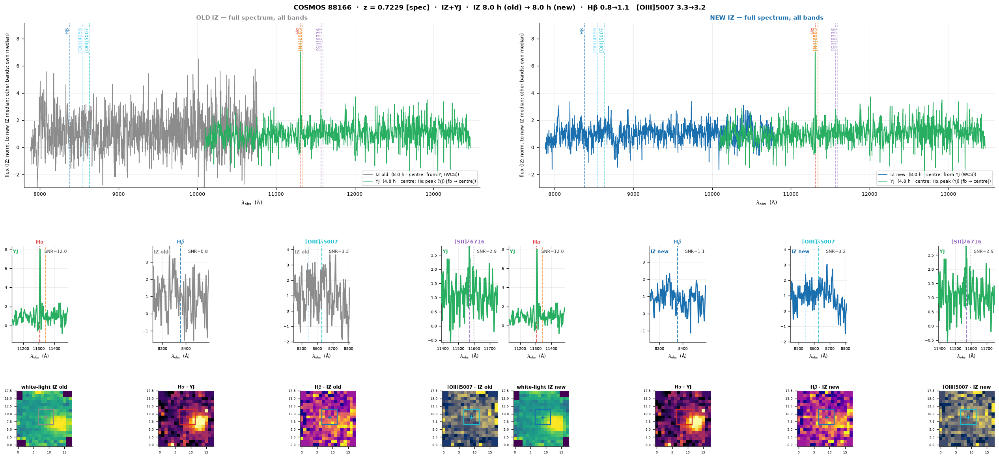

Saved → kmos_iz_compare_detail_COSMOS_88166.pdf


In [6]:
MAP_LINES = [('ha', r'H$\alpha$', HA_REST, '#d62728', 'inferno'),
             ('hb', r'H$\beta$', 0.48627, '#1f77b4', 'plasma'),
             ('oiii', '[OIII]5007', 0.50082, '#17becf', 'cividis')]

def _apt_rect(cy, cx, box=APERTURE, **kw):
    h2 = box // 2
    return Rectangle((cx - h2 - 0.5, cy - h2 - 0.5), box, box, linewidth=1.4, fill=False, **kw)

def _show_map(ax, im, title, m, ec, cmap, clim=None):
    if im is None or not np.isfinite(im).any():
        ax.text(0.5, 0.5, 'not covered', ha='center', va='center', transform=ax.transAxes,
                fontsize=7, color='#aaa', style='italic')
    else:
        f = im[np.isfinite(im)]
        vmin, vmax = clim if clim else (np.nanpercentile(f, 5), np.nanpercentile(f, 97))
        ax.imshow(im, origin='lower', aspect='equal', cmap=cmap, vmin=vmin, vmax=vmax)
        cy, cx = m['ctr']
        ax.plot(cx, cy, '+', ms=6, mew=1.5, color=ec, zorder=5)
        ax.add_patch(_apt_rect(cy, cx, edgecolor=ec, zorder=5))
    ax.set_title(title, fontsize=7, pad=3); ax.tick_params(labelsize=5); ax.grid(False)

def _full_ylim(sides, z):
    lo, hi = [], []
    for mem in sides.values():
        for m in mem:
            s = m['med'][np.isfinite(m['med'])]
            if not s.size:
                continue
            lo.append(np.percentile(s, 1)); hi.append(np.percentile(s, 99.5))
            for k, lrest, *_ in ZOOM_PANELS:
                lam = lrest * (1 + z); win = np.isfinite(m['med']) & (np.abs(m['wave'] - lam) < 0.004)
                if win.any() and fin(m['snr'][k]) >= SNR_MIN:
                    hi.append(np.nanmax(m['med'][win]))
    a, b = min(lo), max(hi)
    return a - 0.12 * (b - a), b + 0.12 * (b - a)

detail = [g for g in galaxies if g['z_type'] in ('spec', 'cluster')
          and max(g['best_old'], g['best_new']) >= SNR_MIN][:TOP_DETAIL]

for g in detail:
    z = g['z']
    io, inew = g['iz_old'], g['iz_new']
    snr_txt = "   ".join(f"{PLAIN[k]} {g['snr']['old'][k]:.1f}→{g['snr']['new'][k]:.1f}"
                         for k, *_ in ZOOM_PANELS
                         if g['use']['new'][k] is not None and g['use']['new'][k]['band'] == BAND
                         and np.isfinite(g['snr']['new'][k]))
    fig = plt.figure(figsize=(21, 10), constrained_layout=True)
    fig.suptitle(f"{g['field']} {g['tid']}  ·  z = {z:.4f} [{g['z_type']}]  ·  "
                 f"{'+'.join([BAND] + [m['band'] for m in g['others']])}  ·  "
                 f"IZ {io['exptime_s']/3600:.1f} h (old) → {inew['exptime_s']/3600:.1f} h (new)  ·  {snr_txt}",
                 fontsize=10, fontweight='bold')
    outer = gridspec.GridSpec(3, 2, figure=fig, height_ratios=[2.0, 1.5, 1.4], hspace=0.4, wspace=0.08)
    yl_full = _full_ylim(g['sides'], z)
    lo_all = min(m['wave'].min() for m in g['sides']['new']); hi_all = max(m['wave'].max() for m in g['sides']['new'])
    zoom_yl = {k: _pair_ylim([g['use']['old'][k], g['use']['new'][k]], lrest, zh, z)
               for k, lrest, _, _, zh, _ in ZOOM_PANELS}
    wl_old = np.nansum(np.where(_erode_valid(np.isfinite(io['cube']), EDGE_MARGIN), io['cube'], np.nan), 0)
    wl_new = np.nansum(np.where(_erode_valid(np.isfinite(inew['cube']), EDGE_MARGIN), inew['cube'], np.nan), 0)

    for col, side in enumerate(('old', 'new')):
        mem = g['sides'][side]
        # ── full spectrum ──
        ax = fig.add_subplot(outer[0, col])
        for m in mem:
            v = np.isfinite(m['med'])
            lab = (f"{m['band']} {side}" if m['band'] == BAND else m['band']) + \
                  f"  ({m['exptime_s']/3600:.1f} h · centre: {m['ctr_src']})"
            ax.plot(m['wave'][v] * 1e4, m['med'][v], color=_col(m), lw=1.0, zorder=3, label=lab)
        for lname, (lrest, lc) in EMISSION_LINES.items():
            lam = lrest * (1 + z)
            if lo_all <= lam <= hi_all and any(m['wave'].min() <= lam <= m['wave'].max() for m in mem):
                ax.axvline(lam * 1e4, color=lc, lw=1.0, ls='--', alpha=0.7)
                ax.text(lam * 1e4, 0.97, lname, transform=ax.get_xaxis_transform(), rotation=90,
                        ha='right', va='top', fontsize=7, color=lc, bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))
        ax.set_xlim(lo_all * 1e4, hi_all * 1e4); ax.set_ylim(*yl_full)
        ax.set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=8)
        ax.set_ylabel('flux (IZ: norm. to new IZ median; other bands: own median)', fontsize=7)
        ax.set_title(f"{'OLD' if side == 'old' else 'NEW'} {BAND} — full spectrum, all bands", fontsize=9,
                     color=OLD_COLOR if side == 'old' else NEW_COLOR)
        ax.tick_params(labelsize=7); ax.legend(fontsize=6.5, loc='lower right', framealpha=0.8)

        # ── line zooms ──
        inner = gridspec.GridSpecFromSubplotSpec(1, len(ZOOM_PANELS), subplot_spec=outer[1, col], wspace=0.3)
        for ci, (lkey, lrest, label, lc, zhalf, comp) in enumerate(ZOOM_PANELS):
            ax = fig.add_subplot(inner[ci]); m = g['use'][side][lkey]
            _panel(ax, m, lkey, lrest, label, lc, zhalf, comp, z, _col(m), zoom_yl[lkey])
            ax.set_title(label, fontsize=8, color=lc, pad=3); ax.tick_params(labelsize=6)
            ax.set_xlabel(r'$\lambda_{\rm obs}$  (Å)', fontsize=7)

        # ── maps: IZ white-light + IZ line maps ──
        izm = io if side == 'old' else inew
        inner = gridspec.GridSpecFromSubplotSpec(1, 1 + len(MAP_LINES), subplot_spec=outer[2, col], wspace=0.3)
        wl = wl_old if side == 'old' else wl_new
        _show_map(fig.add_subplot(inner[0]), wl, f"white-light {BAND} {side}", izm, _col(izm), 'viridis')
        for j, (k, mlabel, mrest, ec, cmap) in enumerate(MAP_LINES):
            m = g['use'][side][k]
            im = narrowband_image(m['cube'], m['wave'], z, mrest) if m is not None else None
            ttl = f"{mlabel} · {m['band']}" + (f" {side}" if m is not None and m['band'] == BAND else '') if m is not None else mlabel
            _show_map(fig.add_subplot(inner[1 + j]), im, ttl, m, ec, cmap)

    fname = f"kmos_iz_compare_detail_{g['field']}_{g['tid']}.pdf"
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")